# De un tamaño medio a una curva: la distribución de Rosin-Rammler y el índice de uniformidad

**Nivel 1: Fundamentos** · Requiere: 02-classical-prediction/01-the-classical-equation-on-one-blast · Tiempo de lectura: unos 20 minutos

## Objetivos

Un tamaño medio es un solo número. Un chancador se especifica contra un percentil, normalmente el P80, así que el modelo clásico agrega una distribución alrededor de la media. Este cuaderno construye esa distribución para un tiro y la lee.

Al terminar habrá:

- escrito la curva de Rosin-Rammler y el índice de uniformidad de Cunningham que la moldea, y coincidido con el motor en el tiro `En1` de Enusa;
- leído el P20, el P50 y el P80 de la curva y comparado la curva con la que versionó la ejecución offline;
- visto cómo varía el índice de uniformidad en los 91 tiros con geometría, y qué le hace a la cola.

## Preparación

Instale los paquetes con los pines exactos de `notebooks/requirements.txt`. El motor es `blastfrag`, publicado en PyPI; los otros paquetes son su base numérica y la biblioteca de gráficos.

```bash
pip install blastfrag==0.4.0 numpy==2.5.3 matplotlib==3.11.2
```

Esta celda aún no importa nada del cuaderno: lee las versiones instaladas desde los metadatos de los paquetes y las imprime, de modo que la salida registra qué motor produjo cada número que sigue.

In [1]:
# Imprima la versión instalada de cada paquete que usa este cuaderno
from importlib.metadata import version

for name in ("blastfrag", "numpy", "matplotlib",):
    print(f"{name}=={version(name)}")

blastfrag==0.4.0
numpy==2.5.3
matplotlib==3.11.2


## Datos

| Fuente | Titular y URL | Clase de licencia | Archivo que lee el cuaderno |
|---|---|---|---|
| El corpus y los patrones reconstruidos | Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 | hechos numéricos reutilizados con cita; el artículo nunca se distribuye | el corpus dentro del paquete `blastfrag` |
| Las ecuaciones de la curva y del índice de uniformidad | Amoako, Jha y Zhong 2022, https://doi.org/10.3390/mining2020013 (Ecs. 5 y 7) | las ecuaciones se reproducen con cita | `bf.rosin_rammler`, `bf.cunningham_uniformity_index` |
| Las distribuciones versionadas del caso Enusa | este repositorio (MIT), escrito por la ejecución offline | la licencia propia del producto | `data/derived/real-enusa/case.json`, campo `distributions` |

Ningún conjunto de datos disponible para este trabajo registra una distribución de tamaños medida: solo se mide el `x50` medio. Las curvas son salida de modelo, y este cuaderno lo dice donde las lee.

## Método

La curva de Rosin-Rammler da la fracción que pasa por una malla de tamaño `x` (Amoako, Jha y Zhong 2022, https://doi.org/10.3390/mining2020013, Ec. 5):

```
P(x) = 1 - exp( -0.693 * (x / x50)^n )
```

El 0,693 es `ln 2`, lo que hace de `x50` el tamaño por el que pasa 50 por ciento. El exponente `n` es el índice de uniformidad: un `n` grande significa un rango de tamaños estrecho y uniforme; un `n` pequeño significa una dispersión amplia con sobretamaño y finos. El índice de Cunningham de 1987 (Ec. 7 del mismo artículo) calcula `n` desde el patrón:

```
n = (2.2 - 14 B/d) * sqrt((1 + S/B) / 2) * (1 - W/B) * (|BCL - CCL| / L + 0.1)^0.1 * (L / H)
```

con el bordo `B` en metros, el diámetro `d` en **milímetros**, el espaciamiento `S`, la desviación de perforación `W`, la longitud de carga `L`, la altura de banco `H` y las longitudes de carga de fondo y de columna `BCL` y `CCL`. Las unidades mixtas son una trampa: `B/d` aquí vale cerca de 0,027 y no el 27 adimensional que tabula el corpus. El motor toma una sola columna continua, así que el término de carga es constante.

### Paso 1: el tamaño medio y el índice de un tiro

La celda toma `En1`, obtiene su patrón y el tamaño medio clásico del tema anterior, y calcula el índice de uniformidad con el motor y a mano, de modo que las unidades mixtas sean visibles.

In [2]:
# Importaciones, el tiro, su tamaño medio clásico y su índice de uniformidad (motor y a mano)
import json
import math
from pathlib import Path

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np

DERIVED = Path("../../../data/derived")
train = bf.load_training_corpus()
blast = next(b for b in train if b.blast_id == "En1")
pattern = bf.reconstruct_pattern(blast)
x50 = bf.Kuznetsov().predict_one(blast).x50_m
n_engine = bf.cunningham_uniformity_index(pattern)

# A mano: bordo en metros sobre diámetro en milímetros, una sola columna continua
b_over_d = pattern.burden_m / pattern.hole_diameter_mm
n_hand = ((2.2 - 14 * b_over_d) * math.sqrt((1 + pattern.spacing_m / pattern.burden_m) / 2)
          * (1 - pattern.drill_deviation_m / pattern.burden_m) * (0.1 ** 0.1) * (pattern.charge_length_m / pattern.bench_height_m))
print(f"x50 = {x50:.4f} m")
print(f"B/d (m per mm) = {b_over_d:.4f}  frente a la razón tabulada {blast.B_over_D}")
print(f"n motor = {n_engine:.4f} | n a mano = {n_hand:.4f} | igual: {abs(n_engine - n_hand) < 1e-12}")

x50 = 0.4399 m
B/d (m per mm) = 0.0273  frente a la razón tabulada 27.27
n motor = 0.6321 | n a mano = 0.6321 | igual: True


### Paso 2: la curva, y lo que lee un chancador de ella

`rosin_rammler` evalúa la curva en la grilla logarítmica compartida de mallas del motor, de 0,1 mm a 3 m. La `SizeDistribution` devuelta puede preguntarse por el tamaño que pasa cualquier fracción. La celda lee el P20, el P50 y el P80, y el tamaño característico por el que pasa 63,2 por ciento.

In [3]:
# Construir la curva y leer sus percentiles
curve = bf.rosin_rammler(x50, n_engine)
print("puntos en la grilla de mallas:", len(curve.sizes_m), "| desde", f"{curve.sizes_m[0]:.4f}", "hasta", f"{curve.sizes_m[-1]:.2f}", "m")
for fraction in (0.2, 0.5, 0.8):
    print(f"P{int(fraction * 100)} = {curve.percentile_m(fraction):.4f} m")
print(f"tamaño característico (pasa 63,2 %) = {curve.detail['characteristic_size_m']:.4f} m")
print(f"fracción que pasa el x50 medido de este tiro ({blast.x50_m} m) = {curve.passing_at(blast.x50_m):.3f}")

puntos en la grilla de mallas: 241 | desde 0.0001 hasta 3.00 m
P20 = 0.0732 m
P50 = 0.4399 m
P80 = 1.6679 m
tamaño característico (pasa 63,2 %) = 0.7855 m
fracción que pasa el x50 medido de este tiro (0.37 m) = 0.463


### Paso 3: comparar con la curva versionada

La ejecución offline escribió la curva de este tiro en `case.json`, redondeada a seis decimales. La celda la compara con la recién construida, punto por punto.

In [4]:
# Mayor diferencia punto a punto contra la curva de Kuz-Ram versionada
artifact = json.loads((DERIVED / "real-enusa" / "case.json").read_text(encoding="utf-8"))
committed = artifact["distributions"]["kuz-ram"]
print("la curva versionada es del tiro:", artifact["representative_blast_id"])
gap = max(abs(a - b) for a, b in zip(curve.passing, committed["passing"]))
print(f"mayor diferencia en la fracción que pasa = {gap:.1e}  (los valores versionados están redondeados a 6 decimales)")
print("P80 versionado =", round(committed["p80_m"], 4), "m | reconstruido =", round(curve.percentile_m(0.8), 4), "m")

la curva versionada es del tiro: En1
mayor diferencia en la fracción que pasa = 5.0e-07  (los valores versionados están redondeados a 6 decimales)
P80 versionado = 1.6679 m | reconstruido = 1.6679 m


### Paso 4: el índice de uniformidad en el corpus

El índice depende solo del patrón. La celda lo calcula para los 91 tiros con geometría y dibuja la curva de tres de ellos: el de menor índice, la mediana y el mayor, con el mismo tamaño medio de modo que solo difiere la forma.

tiros: 91 | n mín 0.184 | mediana 0.950 | máx 1.362


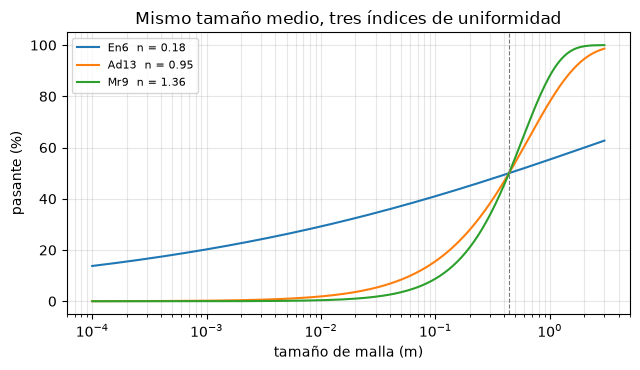

In [5]:
# El índice de uniformidad de cada tiro con geometría, y tres curvas con el mismo tamaño medio
indices = {b.blast_id: bf.cunningham_uniformity_index(bf.reconstruct_pattern(b)) for b in train if bf.has_absolute_geometry(b)}
values = np.array(list(indices.values()))
print("tiros:", len(values), f"| n mín {values.min():.3f} | mediana {np.median(values):.3f} | máx {values.max():.3f}")
ordered = sorted(indices, key=indices.get)
picks = [ordered[0], ordered[len(ordered) // 2], ordered[-1]]
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for pick in picks:
    shape = bf.rosin_rammler(x50, indices[pick])
    ax.plot(shape.sizes_m, [100 * p for p in shape.passing], label=f"{pick}  n = {indices[pick]:.2f}")
ax.axvline(x50, color="#777", lw=0.8, ls="--")
ax.set_xscale("log")
ax.set_xlabel("tamaño de malla (m)")
ax.set_ylabel("pasante (%)")
ax.set_title("Mismo tamaño medio, tres índices de uniformidad")
ax.legend(fontsize=8)
ax.grid(alpha=0.3, which="both")
fig.tight_layout()
plt.show()

## Resultados

**La curva queda fijada por dos números.** El tamaño medio fija dónde la curva cruza 50 por ciento y el índice de uniformidad fija cuán empinadamente sube. Reconstruida a mano y con el motor coinciden, y la curva del motor coincide con la versionada hasta el redondeo del archivo.

**La cola es larga.** Para `En1` el índice de uniformidad está bajo el rango de 0,7 a 2 que Amoako, Jha y Zhong declaran como habitual, así que la curva es ancha: el P80 es varias veces el tamaño medio, mientras que la fracción que pasa el x50 medido (cerca de 46 por ciento, en la salida de arriba) se acerca al 50 por ciento del predicho. En el corpus el índice abarca un factor de siete, de modo que la forma difiere mucho de un tiro a otro incluso con un mismo tamaño medio.

**Qué no muestra esto.** La curva nunca se comparó con una distribución de tamaños medida, porque no hay ninguna disponible: el corpus mide solo el `x50`. Un P80 leído de esta curva es una salida de modelo cuya forma nada aquí valida. Un P80 de este tamaño, mayor que los bloques in situ del sitio, también señala que la curva necesita el tope estructural que introduce el cuaderno siguiente.

## Resumen

- Una curva de Rosin-Rammler necesita el tamaño medio y un índice de uniformidad; el índice viene del patrón, con su trampa de unidades mixtas.
- El motor, un cálculo a mano y el artefacto versionado coinciden en la curva.
- El corpus abarca un amplio rango de índices, de modo que la forma, y el P80, difieren mucho más que la media.
- Siguiente: el cuaderno 02 agrega las curvas Swebrec y de zona de trituración y el tope en el bloque in situ.

## Referencias

- Amoako, Jha y Zhong 2022, https://doi.org/10.3390/mining2020013 (Ecs. 5 y 7)
- Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 (el corpus)
- `blastfrag` 0.4.0, el motor, en PyPI: https://pypi.org/project/blastfrag/